In [1]:
import sys
print(sys.executable)

E:\ecommerce_python\.venv\Scripts\python.exe


In [2]:
import os

data_path = r"E:\ecommerce_python\data"

print(os.listdir(data_path))

['archive.zip', 'olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [3]:
import pandas as pd

orders = pd.read_csv(r"E:\ecommerce_python\data\olist_orders_dataset.csv")

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
orders.shape

(99441, 8)

In [5]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [6]:
orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [7]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

In [8]:
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                           str
order_delivered_carrier_date                str
order_delivered_customer_date               str
order_estimated_delivery_date               str
dtype: object

In [9]:
orders["order_purchase_timestamp"].head()

0   2017-10-02 10:56:33
1   2018-07-24 20:41:37
2   2018-08-08 08:38:49
3   2017-11-18 19:28:06
4   2018-02-13 21:18:39
Name: order_purchase_timestamp, dtype: datetime64[us]

In [10]:
date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column])

In [11]:
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [12]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [13]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [14]:
orders["order_id"].nunique()

99441

In [15]:
len(orders)

99441

In [16]:
print("First order:", orders["order_purchase_timestamp"].min())
print("Last order:", orders["order_purchase_timestamp"].max())

First order: 2016-09-04 21:15:19
Last order: 2018-10-17 17:30:18


In [17]:
orders["order_purchase_timestamp"].dt.year.value_counts().sort_index()

order_purchase_timestamp
2016      329
2017    45101
2018    54011
Name: count, dtype: int64

In [18]:
order_items = pd.read_csv(
    r"E:\ecommerce_python\data\olist_order_items_dataset.csv"
)

order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [19]:
order_items.shape

(112650, 7)

In [20]:
order_items.isna().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [21]:
print("Unique orders:", order_items["order_id"].nunique())
print("Unique products:", order_items["product_id"].nunique())
print("Unique sellers:", order_items["seller_id"].nunique())

Unique orders: 98666
Unique products: 32951
Unique sellers: 3095


In [22]:
order_items["order_item_id"].value_counts().sort_index()

order_item_id
1     98666
2      9803
3      2287
4       965
5       460
6       256
7        58
8        36
9        28
10       25
11       17
12       13
13        8
14        7
15        5
16        3
17        3
18        3
19        3
20        3
21        1
Name: count, dtype: int64

In [23]:
len(order_items) / order_items["order_id"].nunique()

1.1417306873695092

In [24]:
order_items.dtypes

order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

In [25]:
order_items["price"].sum()

np.float64(13591643.7)

In [26]:
order_items["freight_value"].sum()

np.float64(2251909.54)

In [27]:
order_items["total_value"] = (
    order_items["price"] + order_items["freight_value"]
)

order_items["total_value"].sum()

np.float64(15843553.24)

In [28]:
order_items.shape

(112650, 8)

In [29]:
id_counts = order_items["order_id"].value_counts()

id_counts.value_counts().sort_index()

count
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

In [30]:
order_items[["price", "freight_value", "total_value"]].describe()

,price,freight_value,total_value
count,112650.000000,112650.000000,112650.000000
mean,120.653739,19.990320,140.644059
std,183.633928,15.806405,190.724394
min,0.850000,0.000000,6.080000
25%,39.900000,13.080000,55.220000
50%,74.990000,16.260000,92.320000
75%,134.900000,21.150000,157.937500
max,6735.000000,409.680000,6929.310000


In [31]:
order_items_with_status = order_items.merge(
    orders[["order_id", "customer_id", "order_status", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

order_items_with_status.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,total_value,customer_id,order_status,order_purchase_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,72.19,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,259.83,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,216.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,25.78,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,218.04,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51


In [32]:
order_items_with_status.groupby("order_status")["total_value"].agg(
    ["count", "sum"]
).sort_values("sum", ascending=False)

,count,sum
order_status,,
delivered,110197,15419773.75
shipped,1185,177129.34
canceled,542,105885.72
processing,357,69394.11
invoiced,359,68988.75
unavailable,7,2140.49
approved,3,241.08


In [33]:
status_value = (
    order_items_with_status
    .groupby("order_status")["total_value"]
    .sum()
)

(status_value / status_value.sum() * 100).sort_values(ascending=False)

order_status
delivered      97.325224
shipped         1.117990
canceled        0.668321
processing      0.437996
invoiced        0.435437
unavailable     0.013510
approved        0.001522
Name: total_value, dtype: float64

In [34]:
delivered_items = order_items_with_status[
    order_items_with_status["order_status"] == "delivered"
].copy()

delivered_items.shape

(110197, 11)

In [35]:
delivered_items["total_value"].sum()

np.float64(15419773.75)

In [36]:
monthly_sales = (
    delivered_items
    .groupby(
        delivered_items["order_purchase_timestamp"].dt.to_period("M")
    )["total_value"]
    .sum()
)

monthly_sales

order_purchase_timestamp
2016-09        143.46
2016-10      46490.66
2016-12         19.62
2017-01     127482.37
2017-02     271239.32
2017-03     414330.95
2017-04     390812.40
2017-05     566851.40
2017-06     490050.37
2017-07     566299.08
2017-08     645832.36
2017-09     701077.49
2017-10     751117.01
2017-11    1153364.20
2017-12     843078.29
2018-01    1077887.46
2018-02     966168.41
2018-03    1120598.24
2018-04    1132878.93
2018-05    1128774.52
2018-06    1011978.29
2018-07    1027807.28
2018-08     985491.64
Freq: M, Name: total_value, dtype: float64

In [37]:
order_payments = pd.read_csv(
    r"E:\ecommerce_python\data\olist_order_payments_dataset.csv"
)

order_payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [38]:
order_payments.shape

(103886, 5)

In [39]:
payment_counts = order_payments["order_id"].value_counts()

payment_counts.value_counts().sort_index()

count
1     96479
2      2382
3       301
4       108
5        52
6        36
7        28
8        11
9         9
10        5
11        8
12        8
13        3
14        2
15        2
19        2
21        1
22        1
26        1
29        1
Name: count, dtype: int64

In [40]:
order_payments.isna().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [41]:
order_payment_totals = (
    order_payments
    .groupby("order_id")["payment_value"]
    .sum()
    .reset_index()
)

order_payment_totals.head()

,order_id,payment_value
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04


In [42]:
order_payment_totals.shape

(99440, 2)

In [43]:
order_payment_totals["payment_value"].sum()

np.float64(16008872.12)

In [44]:
id="7m2q8k"
order_payment_status = order_payment_totals.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

order_payment_status.groupby("order_status")["payment_value"].agg(
    ["count", "sum"]
).sort_values("sum", ascending=False)

,count,sum
order_status,,
delivered,96477,15422461.77
shipped,1107,177213.96
canceled,625,143255.60
unavailable,609,126479.51
processing,301,69394.11
invoiced,314,69137.99
created,5,688.10
approved,2,241.08


In [45]:
id="h8v3p1"
delivered_payment_check = (
    order_payment_totals
    .merge(
        delivered_items.groupby("order_id")["total_value"].sum().reset_index(),
        on="order_id",
        how="inner"
    )
)

delivered_payment_check["difference"] = (
    delivered_payment_check["payment_value"]
    - delivered_payment_check["total_value"]
)

delivered_payment_check["difference"].describe()

count    96477.000000
mean         0.029349
std          1.138706
min        -51.620000
25%          0.000000
50%          0.000000
75%          0.000000
max        182.810000
Name: difference, dtype: float64

In [46]:
id="9c8w2k"
orders_with_payment = (
    orders
    .merge(
        order_payment_totals,
        on="order_id",
        how="left"
    )
)

orders_with_payment.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,28.62


In [47]:
orders_with_payment["payment_value"].isna().sum()

np.int64(1)

In [48]:
customers = pd.read_csv(
    r"E:\ecommerce_python\data\olist_customers_dataset.csv"
)

customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [49]:
customers.shape

(99441, 5)

In [50]:
customers["customer_id"].nunique()

99441

In [51]:
customers["customer_unique_id"].nunique()

96096

In [52]:
id="4h1j9k"
customer_record_counts = (
    customers["customer_unique_id"]
    .value_counts()
)

customer_record_counts.value_counts().sort_index()

count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

In [53]:
customer_orders = (
    orders_with_payment
    .merge(
        customers[
            [
                "customer_id",
                "customer_unique_id",
                "customer_city",
                "customer_state"
            ]
        ],
        on="customer_id",
        how="left"
    )
)

customer_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_value,customer_unique_id,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,38.71,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,141.46,af07308b275d755c9edb36a90c618231,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,179.12,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,72.20,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,28.62,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP


In [54]:
customer_order_counts = (
    customer_orders["customer_unique_id"]
    .value_counts()
)

customer_order_counts.value_counts().sort_index()

count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

In [55]:
delivered_customer_orders = customer_orders[
    customer_orders["order_status"] == "delivered"
].copy()

delivered_customer_orders.shape

(96478, 12)

In [56]:
delivered_order_counts = (
    delivered_customer_orders["customer_unique_id"]
    .value_counts()
)

delivered_order_counts.value_counts().sort_index()

count
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

In [57]:
customer_sales = (
    delivered_customer_orders
    .groupby("customer_unique_id")["payment_value"]
    .sum()
)

customer_sales.head()

customer_unique_id
0000366f3b9a7992bf8c76cfdf3221e2    141.90
0000b849f77a49e4a4ce2b2a4ca5be3f     27.19
0000f46a3911fa3c0805444483337064     86.22
0000f6ccb0745a6a4b88665a16c9f078     43.62
0004aac84e0df4da2b147fca70cf8255    196.89
Name: payment_value, dtype: float64

In [58]:
customer_sales.describe()

count    93358.000000
mean       165.197003
std        226.314012
min          0.000000
25%         63.052500
50%        107.780000
75%        182.557500
max      13664.080000
Name: payment_value, dtype: float64

In [59]:
id="z8j3k2"
delivered_customer_orders[
    delivered_customer_orders["payment_value"].isna()
]["customer_unique_id"].nunique()

1

In [60]:
delivered_customer_orders[
    delivered_customer_orders["payment_value"].isna()
][["order_id", "customer_unique_id", "order_status"]]

,order_id,customer_unique_id,order_status
30710,bfbd0f9bdef84302105ad712db648a6c,830d5b7aaa3b6f1e9ad63703bec97d23,delivered


In [61]:
total_customers = delivered_order_counts.size

repeat_customers = (delivered_order_counts > 1).sum()

repeat_rate = repeat_customers / total_customers * 100

print("Total customers:", total_customers)
print("Repeat customers:", repeat_customers)
print("Repeat customer rate:", round(repeat_rate, 2), "%")

Total customers: 93358
Repeat customers: 2801
Repeat customer rate: 3.0 %


In [62]:
import numpy as np

In [63]:
customer_summary = pd.DataFrame({
    "orders": delivered_order_counts,
    "sales": customer_sales
})

customer_summary["customer_type"] = np.where(
    customer_summary["orders"] > 1,
    "Repeat",
    "One-time"
)

customer_summary.groupby("customer_type")["sales"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
customer_type,,,
One-time,90557,14558104.56,160.761781
Repeat,2801,864357.21,308.588793


In [64]:
customer_sales_share = (
    customer_summary.groupby("customer_type")["sales"].sum()
    / customer_summary["sales"].sum()
    * 100
)

customer_sales_share

customer_type
One-time    94.395465
Repeat       5.604535
Name: sales, dtype: float64

In [65]:
state_sales = (
    delivered_customer_orders
    .groupby("customer_state")["payment_value"]
    .sum()
    .sort_values(ascending=False)
)

state_sales.head(10)

customer_state
SP    5770266.19
RJ    2055690.45
MG    1819277.61
RS     861802.40
PR     781919.55
SC     595208.40
BA     591270.60
DF     346146.17
GO     334294.22
ES     317682.65
Name: payment_value, dtype: float64

In [66]:
top_10_state_sales_share = (
    state_sales.head(10).sum()
    / state_sales.sum()
    * 100
)

print("Top 10 state sales share:", round(top_10_state_sales_share, 2), "%")

Top 10 state sales share: 87.36 %


In [67]:
state_customer_summary = (
    delivered_customer_orders
    .groupby("customer_state")
    .agg(
        customers=("customer_unique_id", "nunique"),
        sales=("payment_value", "sum")
    )
)

state_customer_summary["sales_per_customer"] = (
    state_customer_summary["sales"]
    / state_customer_summary["customers"]
)

state_customer_summary.sort_values(
    "sales_per_customer",
    ascending=False
).head(10)

,customers,sales,sales_per_customer
customer_state,,,
PB,504,137834.65,273.481448
AC,76,19586.25,257.713816
RO,231,56975.70,246.648052
AP,66,16141.81,244.572879
AL,387,94195.79,243.399974
PA,922,212027.55,229.964805
PI,464,105272.17,226.879677
RR,40,9039.52,225.988000
TO,267,60007.37,224.746704


In [68]:
state_customer_summary[
    state_customer_summary["customers"] >= 500
].sort_values(
    "sales_per_customer",
    ascending=False
)

,customers,sales,sales_per_customer
customer_state,,,
PB,504,137834.65,273.481448
PA,922,212027.55,229.964805
MT,856,181441.72,211.964626
CE,1258,266463.97,211.815556
MA,700,147807.29,211.153271
PE,1551,309074.59,199.274397
MS,681,134421.54,197.388458
BA,3158,591270.60,187.229449
GO,1895,334294.22,176.408559


In [69]:
products = pd.read_csv(
    r"E:\ecommerce_python\data\olist_products_dataset.csv"
)

products.shape

(32951, 9)

In [70]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')

In [71]:
products.isna().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [72]:
products["product_category_name"].value_counts(dropna=False).head(20)

product_category_name
cama_mesa_banho                      3029
esporte_lazer                        2867
moveis_decoracao                     2657
beleza_saude                         2444
utilidades_domesticas                2335
automotivo                           1900
informatica_acessorios               1639
brinquedos                           1411
relogios_presentes                   1329
telefonia                            1134
bebes                                 919
perfumaria                            868
papelaria                             849
fashion_bolsas_e_acessorios           849
cool_stuff                            789
ferramentas_jardim                    753
pet_shop                              719
NaN                                   610
eletronicos                           517
construcao_ferramentas_construcao     400
Name: count, dtype: int64

In [73]:
print(products.shape)
print(order_items.shape)

(32951, 9)
(112650, 8)


In [74]:
order_items_with_products = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

In [75]:
order_items_with_products.shape

(112650, 9)

In [76]:
order_items_with_products[
    ["order_id", "product_id", "price", "product_category_name"]
].head(10)

,order_id,product_id,price,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,58.90,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,239.90,pet_shop
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,199.00,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,12.99,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,199.90,ferramentas_jardim
5,00048cc3ae777c65dbb7d2a0634bc1ea,ef92defde845ab8450f9d70c526ef70f,21.90,utilidades_domesticas
6,00054e8431b9d7675808bcb819fb4a32,8d4f2bb7e93e6710a28f34fa83ee7d28,19.90,telefonia
7,000576fe39319847cbb9d288c5617fa6,557d850972a7d6f792fd18ae1400d9b6,810.00,ferramentas_jardim
8,0005a1a1728c9d785b8e2b08b904576c,310ae3c140ff94b03219ad0adc3c778f,145.95,beleza_saude
9,0005f50442cb953dcd1d21e1fb923495,4535b0e1091c278dfd193e5a1d63b39f,53.99,livros_tecnicos


In [77]:
category_sales = (
    order_items_with_products
    .groupby("product_category_name")["total_value"]
    .sum()
    .sort_values(ascending=False)
)

category_sales.head(10)

product_category_name
beleza_saude              1441248.07
relogios_presentes        1305541.61
cama_mesa_banho           1241681.72
esporte_lazer             1156656.48
informatica_acessorios    1059272.40
moveis_decoracao           902511.79
utilidades_domesticas      778397.77
cool_stuff                 719329.95
automotivo                 685384.32
ferramentas_jardim         584219.21
Name: total_value, dtype: float64

In [78]:
category_volume = (
    order_items_with_products
    .groupby("product_category_name")
    .agg(
        items_sold=("product_id", "count"),
        sales=("total_value", "sum")
    )
    .sort_values("sales", ascending=False)
)

category_volume.head(10)

,items_sold,sales
product_category_name,,
beleza_saude,9670,1441248.07
relogios_presentes,5991,1305541.61
cama_mesa_banho,11115,1241681.72
esporte_lazer,8641,1156656.48
informatica_acessorios,7827,1059272.40
moveis_decoracao,8334,902511.79
utilidades_domesticas,6964,778397.77
cool_stuff,3796,719329.95
automotivo,4235,685384.32


In [79]:
category_volume["avg_value_per_item"] = (
    category_volume["sales"] / category_volume["items_sold"]
)

category_volume.sort_values(
    "avg_value_per_item",
    ascending=False
).head(10)

,items_sold,sales,avg_value_per_item
product_category_name,,,
pcs,203,232799.43,1146.795222
portateis_casa_forno_e_cafe,76,50193.57,660.441711
eletrodomesticos_2,238,123917.92,520.663529
agro_industria_e_comercio,212,78374.07,369.689009
instrumentos_musicais,680,210137.37,309.025544
eletroportateis,679,206668.83,304.372356
portateis_cozinha_e_preparadores_de_alimentos,15,4278.29,285.219333
telefonia_fixa,264,64220.81,243.260644
construcao_ferramentas_seguranca,194,44463.62,229.193918


In [80]:
category_volume[
    category_volume["items_sold"] >= 500
].sort_values(
    "avg_value_per_item",
    ascending=False
).head(15)

,items_sold,sales,avg_value_per_item
product_category_name,,,
instrumentos_musicais,680,210137.37,309.025544
eletroportateis,679,206668.83,304.372356
relogios_presentes,5991,1305541.61,217.917144
moveis_escritorio,1691,342532.65,202.562182
cool_stuff,3796,719329.95,189.496826
construcao_ferramentas_construcao,929,165328.00,177.963402
moveis_sala,503,86884.73,172.733062
automotivo,4235,685384.32,161.838092
casa_construcao,604,96920.36,160.464172


In [81]:
delivered_items_with_products = delivered_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

In [82]:
delivered_items_with_products.shape

(110197, 12)

In [83]:
delivered_category_sales = (
    delivered_items_with_products
    .groupby("product_category_name")["total_value"]
    .sum()
    .sort_values(ascending=False)
)

delivered_category_sales.head(10)

product_category_name
beleza_saude              1412089.53
relogios_presentes        1264333.12
cama_mesa_banho           1225209.26
esporte_lazer             1118256.91
informatica_acessorios    1032723.77
moveis_decoracao           880329.92
utilidades_domesticas      758392.25
cool_stuff                 691680.89
automotivo                 669454.75
ferramentas_jardim         567145.68
Name: total_value, dtype: float64

In [84]:
delivered_category_volume = (
    delivered_items_with_products
    .groupby("product_category_name")
    .agg(
        items_sold=("product_id", "count"),
        delivered_value=("total_value", "sum")
    )
    .sort_values("delivered_value", ascending=False)
)

delivered_category_volume.head(10)

,items_sold,delivered_value
product_category_name,,
beleza_saude,9465,1412089.53
relogios_presentes,5859,1264333.12
cama_mesa_banho,10953,1225209.26
esporte_lazer,8431,1118256.91
informatica_acessorios,7644,1032723.77
moveis_decoracao,8160,880329.92
utilidades_domesticas,6795,758392.25
cool_stuff,3718,691680.89
automotivo,4140,669454.75


In [85]:
delivered_category_volume["avg_value_per_item"] = (
    delivered_category_volume["delivered_value"]
    / delivered_category_volume["items_sold"]
)

delivered_category_volume.head(10)

,items_sold,delivered_value,avg_value_per_item
product_category_name,,,
beleza_saude,9465,1412089.53,149.190653
relogios_presentes,5859,1264333.12,215.793330
cama_mesa_banho,10953,1225209.26,111.860610
esporte_lazer,8431,1118256.91,132.636331
informatica_acessorios,7644,1032723.77,135.102534
moveis_decoracao,8160,880329.92,107.883569
utilidades_domesticas,6795,758392.25,111.610338
cool_stuff,3718,691680.89,186.035742
automotivo,4140,669454.75,161.704046


In [86]:
filtered_category_value = delivered_category_volume[
    delivered_category_volume["items_sold"] >= 500
].copy()

filtered_category_value.sort_values(
    "avg_value_per_item",
    ascending=False
).head(10)

,items_sold,delivered_value,avg_value_per_item
product_category_name,,,
instrumentos_musicais,651,202187.12,310.579293
eletroportateis,658,198108.47,301.076702
relogios_presentes,5859,1264333.12,215.793330
moveis_escritorio,1668,335211.36,200.966043
cool_stuff,3718,691680.89,186.035742
construcao_ferramentas_construcao,916,162382.01,177.272937
automotivo,4140,669454.75,161.704046
casa_construcao,596,95022.37,159.433507
malas_acessorios,1077,168778.12,156.711346


In [87]:
product_sales = (
    delivered_items_with_products
    .groupby("product_id")
    .agg(
        items_sold=("product_id", "count"),
        delivered_value=("total_value", "sum")
    )
    .sort_values("delivered_value", ascending=False)
)

product_sales.head(10)

,items_sold,delivered_value
product_id,,
bb50f2e236e5eea0100680137654686c,194,67258.03
d1c427060a0f73f6b889a5c7c61f2ac4,332,58957.31
6cdd53843498f92890544667809f1595,153,57933.73
99a4788cb24856965c36a24e339b6058,477,49907.50
3dd2a17168ec895c781a9191c1e95ad7,272,47876.06
d6160fb7873f184099d9bc95e30376af,33,47314.18
aca2eb7d00ea1a7b8ebd4e68314663af,520,44197.75
5f504b3a1c75b73d6151be81eb05bdc9,63,41725.81
25c38557cf793876c5abdd5931f922db,38,40311.95


In [88]:
top_products = (
    product_sales
    .head(10)
    .reset_index()
    .merge(
        products[
            [
                "product_id",
                "product_category_name",
                "product_weight_g",
                "product_photos_qty"
            ]
        ],
        on="product_id",
        how="left"
    )
)

top_products

,product_id,items_sold,delivered_value,product_category_name,product_weight_g,product_photos_qty
0,bb50f2e236e5eea0100680137654686c,194,67258.03,beleza_saude,400.0,6.0
1,d1c427060a0f73f6b889a5c7c61f2ac4,332,58957.31,informatica_acessorios,6550.0,1.0
2,6cdd53843498f92890544667809f1595,153,57933.73,beleza_saude,900.0,1.0
3,99a4788cb24856965c36a24e339b6058,477,49907.50,cama_mesa_banho,1383.0,1.0
4,3dd2a17168ec895c781a9191c1e95ad7,272,47876.06,informatica_acessorios,533.0,1.0
5,d6160fb7873f184099d9bc95e30376af,33,47314.18,pcs,2600.0,4.0
6,aca2eb7d00ea1a7b8ebd4e68314663af,520,44197.75,moveis_decoracao,2600.0,6.0
7,5f504b3a1c75b73d6151be81eb05bdc9,63,41725.81,cool_stuff,15350.0,3.0
8,25c38557cf793876c5abdd5931f922db,38,40311.95,bebes,15800.0,5.0
9,53b36df67ebb7c41585e8d54d6772e08,321,39713.49,relogios_presentes,584.0,3.0


In [89]:
top_products = top_products.set_index("product_id")

top_products

,items_sold,delivered_value,product_category_name,product_weight_g,product_photos_qty
product_id,,,,,
bb50f2e236e5eea0100680137654686c,194,67258.03,beleza_saude,400.0,6.0
d1c427060a0f73f6b889a5c7c61f2ac4,332,58957.31,informatica_acessorios,6550.0,1.0
6cdd53843498f92890544667809f1595,153,57933.73,beleza_saude,900.0,1.0
99a4788cb24856965c36a24e339b6058,477,49907.50,cama_mesa_banho,1383.0,1.0
3dd2a17168ec895c781a9191c1e95ad7,272,47876.06,informatica_acessorios,533.0,1.0
d6160fb7873f184099d9bc95e30376af,33,47314.18,pcs,2600.0,4.0
aca2eb7d00ea1a7b8ebd4e68314663af,520,44197.75,moveis_decoracao,2600.0,6.0
5f504b3a1c75b73d6151be81eb05bdc9,63,41725.81,cool_stuff,15350.0,3.0
25c38557cf793876c5abdd5931f922db,38,40311.95,bebes,15800.0,5.0


In [90]:
top_products["avg_value_per_item"] = (
    top_products["delivered_value"]
    / top_products["items_sold"]
)

top_products.sort_values(
    "avg_value_per_item",
    ascending=False
)

,items_sold,delivered_value,product_category_name,product_weight_g,product_photos_qty,avg_value_per_item
product_id,,,,,,
d6160fb7873f184099d9bc95e30376af,33,47314.18,pcs,2600.0,4.0,1433.763030
25c38557cf793876c5abdd5931f922db,38,40311.95,bebes,15800.0,5.0,1060.840789
5f504b3a1c75b73d6151be81eb05bdc9,63,41725.81,cool_stuff,15350.0,3.0,662.314444
6cdd53843498f92890544667809f1595,153,57933.73,beleza_saude,900.0,1.0,378.651830
bb50f2e236e5eea0100680137654686c,194,67258.03,beleza_saude,400.0,6.0,346.690876
d1c427060a0f73f6b889a5c7c61f2ac4,332,58957.31,informatica_acessorios,6550.0,1.0,177.582259
3dd2a17168ec895c781a9191c1e95ad7,272,47876.06,informatica_acessorios,533.0,1.0,176.014926
53b36df67ebb7c41585e8d54d6772e08,321,39713.49,relogios_presentes,584.0,3.0,123.718037
99a4788cb24856965c36a24e339b6058,477,49907.50,cama_mesa_banho,1383.0,1.0,104.627883


In [91]:
category_translation = pd.read_csv(
    r"E:\ecommerce_python\data\product_category_name_translation.csv"
)

category_translation.head()


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [92]:
top_products = (
    top_products
    .reset_index()
    .merge(
        category_translation,
        on="product_category_name",
        how="left"
    )
    .set_index("product_id")
)

top_products

,items_sold,delivered_value,product_category_name,product_weight_g,product_photos_qty,avg_value_per_item,product_category_name_english
product_id,,,,,,,
bb50f2e236e5eea0100680137654686c,194,67258.03,beleza_saude,400.0,6.0,346.690876,health_beauty
d1c427060a0f73f6b889a5c7c61f2ac4,332,58957.31,informatica_acessorios,6550.0,1.0,177.582259,computers_accessories
6cdd53843498f92890544667809f1595,153,57933.73,beleza_saude,900.0,1.0,378.651830,health_beauty
99a4788cb24856965c36a24e339b6058,477,49907.50,cama_mesa_banho,1383.0,1.0,104.627883,bed_bath_table
3dd2a17168ec895c781a9191c1e95ad7,272,47876.06,informatica_acessorios,533.0,1.0,176.014926,computers_accessories
d6160fb7873f184099d9bc95e30376af,33,47314.18,pcs,2600.0,4.0,1433.763030,computers
aca2eb7d00ea1a7b8ebd4e68314663af,520,44197.75,moveis_decoracao,2600.0,6.0,84.995673,furniture_decor
5f504b3a1c75b73d6151be81eb05bdc9,63,41725.81,cool_stuff,15350.0,3.0,662.314444,cool_stuff
25c38557cf793876c5abdd5931f922db,38,40311.95,bebes,15800.0,5.0,1060.840789,baby


In [93]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

delivered_orders["delivery_days"].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64

In [94]:

delivery_dates_available = (
    delivered_orders["order_delivered_customer_date"].notna()
    & delivered_orders["order_estimated_delivery_date"].notna()
)

delivered_orders["late_delivery"] = pd.Series(
    pd.NA,
    index=delivered_orders.index,
    dtype="boolean"
)

delivered_orders.loc[delivery_dates_available, "late_delivery"] = (
    delivered_orders.loc[
        delivery_dates_available,
        "order_delivered_customer_date"
    ]
    >
    delivered_orders.loc[
        delivery_dates_available,
        "order_estimated_delivery_date"
    ]
)

delivered_orders["late_delivery"].value_counts(dropna=False)


late_delivery
False    88644
True      7826
<NA>         8
Name: count, dtype: Int64

In [95]:
delivered_orders["delay_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / (60 * 60 * 24)

late_orders = delivered_orders[
    delivered_orders["late_delivery"] == True
]

late_orders["delay_days"].describe()

count    7826.000000
mean        9.551776
std        13.952540
min         0.002500
25%         1.867179
50%         5.806481
75%        11.820978
max       188.975081
Name: delay_days, dtype: float64

In [96]:
order_reviews = pd.read_csv(
    r"E:\ecommerce_python\data\olist_order_reviews_dataset.csv"
)

order_reviews.shape


(99224, 7)

In [97]:
order_reviews["order_id"].nunique(), len(order_reviews)

(98673, 99224)

In [98]:
review_counts = (
    order_reviews
    .groupby("order_id")
    .size()
)

review_counts.value_counts().sort_index()


1    98126
2      543
3        4
Name: count, dtype: int64

In [99]:
order_review_summary = (
    order_reviews
    .groupby("order_id")["review_score"]
    .mean()
    .reset_index()
)

order_review_summary.head()

,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0


In [100]:
delivered_with_reviews = delivered_orders.merge(
    order_review_summary,
    on="order_id",
    how="left"
)

delivered_with_reviews.shape

(96478, 12)

In [101]:
delivered_with_reviews.groupby(
    "late_delivery"
)["review_score"].mean()

late_delivery
False    4.294292
True     2.566506
Name: review_score, dtype: float64

In [102]:
delivered_with_reviews["delay_bucket"] = pd.cut(
    delivered_with_reviews["delay_days"],
    bins=[-float("inf"), 0, 3, 7, 14, float("inf")],
    labels=[
        "On time",
        "1–3 days late",
        "4–7 days late",
        "8–14 days late",
        "15+ days late"
    ]
)

delivered_with_reviews.groupby(
    "delay_bucket",
    observed=True
)["review_score"].mean()

delay_bucket
On time           4.294292
1–3 days late     3.766882
4–7 days late     2.317259
8–14 days late    1.745423
15+ days late     1.710771
Name: review_score, dtype: float64

In [103]:
review_distribution = pd.crosstab(
    delivered_with_reviews["delay_bucket"],
    delivered_with_reviews["review_score"],
    normalize="index"
) * 100

review_distribution.round(1)

review_score,1.000000,1.500000,2.000000,2.500000,3.000000,3.333333,3.500000,4.000000,4.333333,4.500000,5.000000
delay_bucket,,,,,,,,,,,
On time,6.6,0.0,2.6,0.0,8.0,0.0,0.0,20.3,0.0,0.1,62.4
1–3 days late,13.7,0.0,5.4,0.0,14.5,0.0,0.1,23.1,0.0,0.1,43.1
4–7 days late,53.0,0.0,8.2,0.0,10.8,0.0,0.1,9.8,0.0,0.0,18.1
8–14 days late,68.0,0.0,10.0,0.1,9.1,0.0,0.0,4.9,0.0,0.0,7.9
15+ days late,69.3,0.1,9.2,0.2,8.9,0.0,0.0,5.3,0.0,0.0,7.0


In [104]:
order_reviews["review_score"].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

In [105]:
category_reviews = (
    delivered_items_with_products[
        ["order_id", "product_category_name"]
    ]
    .drop_duplicates()
    .merge(
        order_review_summary,
        on="order_id",
        how="inner"
    )
)

category_reviews.shape

(96624, 3)

In [106]:
category_review_summary = (
    category_reviews
    .groupby("product_category_name")
    .agg(
        orders=("order_id", "nunique"),
        avg_review_score=("review_score", "mean")
    )
    .sort_values("avg_review_score", ascending=False)
)

category_review_summary.head(10)

,orders,avg_review_score
product_category_name,,
fashion_roupa_infanto_juvenil,7,5.000000
cds_dvds_musicais,12,4.666667
livros_interesse_geral,492,4.534553
alimentos_bebidas,221,4.445701
livros_importados,50,4.440000
portateis_casa_forno_e_cafe,72,4.430556
livros_tecnicos,255,4.427451
construcao_ferramentas_ferramentas,94,4.425532
flores,28,4.392857


In [107]:
category_review_summary_500 = category_review_summary[
    category_review_summary["orders"] >= 500
]

category_review_summary_500.head(10)

,orders,avg_review_score
product_category_name,,
malas_acessorios,1015,4.370443
papelaria,2251,4.294758
pet_shop,1680,4.273810
perfumaria,3076,4.260891
eletroportateis,604,4.256623
fashion_bolsas_e_acessorios,1811,4.242131
brinquedos,3774,4.238341
instrumentos_musicais,605,4.234711
beleza_saude,8601,4.229489


In [108]:
category_review_summary_500.sort_values(
    "avg_review_score",
    ascending=True
).head(10)

,orders,avg_review_score
product_category_name,,
moveis_escritorio,1244,3.642685
cama_mesa_banho,9177,3.999292
telefonia,4069,4.051855
moveis_decoracao,6260,4.057987
informatica_acessorios,6499,4.081243
bebes,2787,4.103516
relogios_presentes,5454,4.121195
eletronicos,2498,4.124500
construcao_ferramentas_construcao,731,4.125171


In [109]:
category_order_pairs = (
    delivered_items_with_products[
        ["order_id", "product_category_name"]
    ]
    .drop_duplicates()
)

category_reviews_raw = category_order_pairs.merge(
    order_reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

category_one_star_raw = (
    category_reviews_raw
    .groupby("product_category_name")
    .agg(
        review_records=("review_score", "size"),
        one_star_rate=(
            "review_score",
            lambda scores: (scores == 1).mean() * 100
        )
    )
)

category_one_star_raw = category_one_star_raw[
    category_one_star_raw["review_records"] >= 500
].sort_values("one_star_rate", ascending=False)

category_one_star_raw.head(10).round(2)

,review_records,one_star_rate
product_category_name,,
moveis_escritorio,1249,17.21
cama_mesa_banho,9295,12.06
moveis_decoracao,6317,11.60
informatica_acessorios,6549,11.28
bebes,2795,10.91
construcao_ferramentas_construcao,732,10.79
telefonia,4073,10.43
relogios_presentes,5464,10.36
eletronicos,2499,9.96


In [110]:
category_one_star_raw.nlargest(10, "one_star_rate")

,review_records,one_star_rate
product_category_name,,
moveis_escritorio,1249,17.213771
cama_mesa_banho,9295,12.060247
moveis_decoracao,6317,11.603609
informatica_acessorios,6549,11.284166
bebes,2795,10.912343
construcao_ferramentas_construcao,732,10.792350
telefonia,4073,10.434569
relogios_presentes,5464,10.358712
eletronicos,2499,9.963986


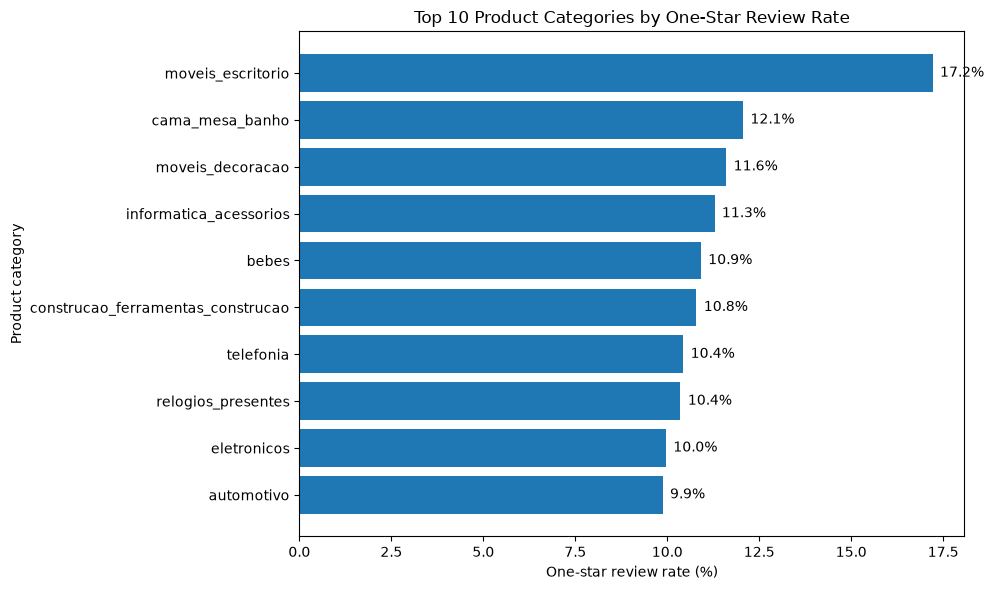

In [119]:
import matplotlib.pyplot as plt

chart_data = category_one_star_raw.nlargest(
    10, "one_star_rate"
).sort_values("one_star_rate")

plt.figure(figsize=(10, 6))

plt.barh(
    chart_data.index,
    chart_data["one_star_rate"]
)

plt.xlabel("One-star review rate (%)")
plt.ylabel("Product category")
plt.title("Top 10 Product Categories by One-Star Review Rate")

for position, value in enumerate(chart_data["one_star_rate"]):
    plt.text(value + 0.2, position, f"{value:.1f}%", va="center")

plt.tight_layout()
plt.savefig(
    "../images/top_product_categories.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

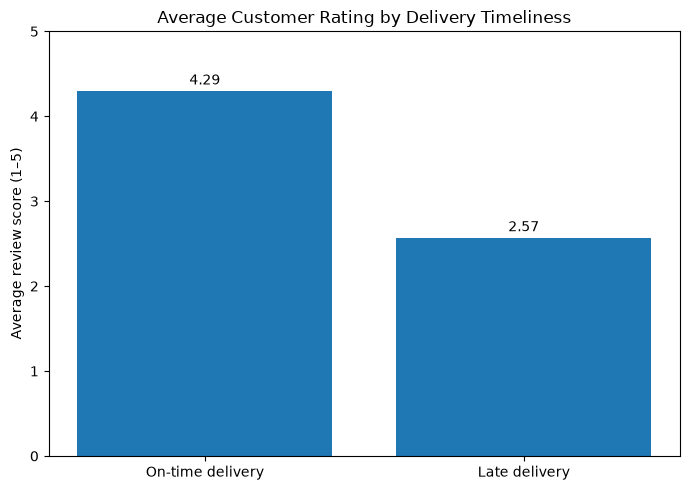

In [120]:
delivery_review_summary = (
    delivered_with_reviews.groupby("late_delivery")["review_score"]
    .mean()
    .rename(index={False: "On-time delivery", True: "Late delivery"})
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    delivery_review_summary.index,
    delivery_review_summary.values
)

plt.ylabel("Average review score (1–5)")
plt.title("Average Customer Rating by Delivery Timeliness")
plt.ylim(0, 5)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{bar.get_height():.2f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    "../images/delivery_review_scores.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [113]:
print("Notebook validation")
print("-" * 35)

print("Orders loaded:", len(orders))
print("Order items loaded:", len(order_items))
print("Delivered orders:", len(delivered_orders))
print("Unique delivered customers:", delivered_customer_orders["customer_unique_id"].nunique())

print("\nDelivery performance:")
print("On-time rate (%):", round((~delivered_orders["late_delivery"]).mean() * 100, 2))

print("\nHighest one-star review rate:")
print(category_one_star_raw.nlargest(1, "one_star_rate"))

print("\nMonthly sales records:", len(monthly_sales))

Notebook validation
-----------------------------------
Orders loaded: 99441
Order items loaded: 112650
Delivered orders: 96478
Unique delivered customers: 93358

Delivery performance:
On-time rate (%): 91.89

Highest one-star review rate:
                       review_records  one_star_rate
product_category_name                               
moveis_escritorio                1249      17.213771

Monthly sales records: 23
